# Process Mining on Bitcoin Agent Event Log with PM4Py

This notebook analyzes the Bitcoin mining-pool agent event log from five angles:

1. Discover the agent decision process.
2. Check conformance against the intended behavior model.
3. Compare variants by agent type.
4. Analyze the decision point: skip vs mine.
5. Link process outcomes to profitability and market conditions.

## Important interpretation note

The case notion used here is:

> one agent / mining-pool decision for one block opportunity

So a case is not one physical production order. It is one simulated agent-block decision process.

Also, the events inside one case often share the same timestamp. Therefore, this notebook avoids activity-duration/performance mining and focuses on:
- control-flow variants,
- conformance logic,
- agent archetype comparison,
- decision mining,
- outcome/profit analysis,
- market-condition analysis.

## 0. Setup

Run the install cell once if PM4Py is not installed in your environment.

For a local environment, recommended Python version is 3.10 or newer.

In [11]:
# Uncomment and run once if needed:
#%pip install pm4py pandas numpy matplotlib scikit-learn

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin' # Adjust the path to Graphviz if needed

try:
    import pm4py
    PM4PY_AVAILABLE = True
    print("PM4Py version:", getattr(pm4py, "__version__", "unknown"))
except ModuleNotFoundError:
    PM4PY_AVAILABLE = False
    print("PM4Py is not installed. Run the install cell above and restart the notebook kernel.")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

OUTPUT_DIR = Path("pm4py_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# The notebook first looks for the dataset in the same folder as the notebook.
# In ChatGPT's sandbox it also works with /mnt/data/.
DATA_PATH = Path("bitcoin_agent_event_log_historical_playthrough_archetypes.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv")

print(DATA_PATH)

import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin' # Adjust the path to Graphviz if needed

PM4Py version: 2.7.22.4


WindowsPath('MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv')

## 1. Load and inspect the event log

Required process-mining columns in this dataset:

| Dataset column | Process-mining meaning |
|---|---|
| `case_id` | Case identifier: one agent-block decision |
| `activity` | Activity name |
| `timestamp` | Event timestamp |
| `event_id` | Ordering column inside and across cases |
| `agent_name` | Resource / mining-pool agent |
| `agent_type` | Organizational group / archetype |

In [5]:
df = pd.read_csv(DATA_PATH)

print("Rows / events:", len(df))
print("Columns:", len(df.columns))
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows / events: 1124292
Columns: 27


,event_id,step,case_id,activity,timestamp,agent_name,agent_type,block_height,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,active,selected_allocation,potential_hashrate_th_s,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,realized_cost_usd,cumulative_profit_usd,reward_btc,realized_revenue_usd
0,1,0,Type 1_001_block_895275,Observe_Market,2025-05-05 00:54:38+00:00,Type 1_001,Type 1: Dominant low-cost pools,895275.0,94723.8,0.010113,3.135113,5.183333,8.526674e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0,Type 1_001_block_895275,Evaluate_Hashrate_Allocation,2025-05-05 00:54:38+00:00,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12544.882546,2513.677484,10031.205062,10031.205062,NaN,NaN,NaN,NaN
2,3,0,Type 1_001_block_895275,Choose_Hashrate_Allocation,2025-05-05 00:54:38+00:00,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,True,1.1,NaN,3.601919e+07,819385.789655,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,0,Type 1_002_block_895275,Observe_Market,2025-05-05 00:54:38+00:00,Type 1_002,Type 1: Dominant low-cost pools,895275.0,94723.8,0.010113,3.135113,5.183333,8.526674e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,0,Type 1_002_block_895275,Evaluate_Hashrate_Allocation,2025-05-05 00:54:38+00:00,Type 1_002,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,True,1.1,3.213414e+07,3.534755e+07,816611.386514,0.041455,12310.959971,2310.627605,10000.332365,10000.332365,NaN,NaN,NaN,NaN


,dtype
event_id,int64
step,int64
case_id,str
activity,str
timestamp,str
agent_name,str
agent_type,str
block_height,float64
btc_price_at_block,float64
transaction_fees_btc,float64


In [6]:
# Basic data quality checks
required_cols = ["case_id", "activity", "timestamp", "event_id", "agent_name", "agent_type"]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"Missing required columns: {missing}"

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")

overview = pd.DataFrame({
    "metric": [
        "events",
        "cases",
        "activities",
        "agents",
        "agent types",
        "blocks / steps",
        "timestamp min",
        "timestamp max",
        "missing timestamps"
    ],
    "value": [
        len(df),
        df["case_id"].nunique(),
        df["activity"].nunique(),
        df["agent_name"].nunique(),
        df["agent_type"].nunique(),
        df["step"].nunique() if "step" in df.columns else np.nan,
        df["timestamp"].min(),
        df["timestamp"].max(),
        df["timestamp"].isna().sum()
    ]
})
display(overview)
display(df["activity"].value_counts().rename_axis("activity").reset_index(name="events"))
display(df["agent_type"].value_counts().rename_axis("agent_type").reset_index(name="events"))

,metric,value
0,events,1124292
1,cases,187200
2,activities,10
3,agents,130
4,agent types,4
5,blocks / steps,1440
6,timestamp min,2025-05-05 00:54:38+00:00
7,timestamp max,2025-05-14 20:06:04+00:00
8,missing timestamps,0


,activity,events
0,Observe_Market,187200
1,Evaluate_Hashrate_Allocation,187200
2,Choose_Hashrate_Allocation,187200
3,Start_Mining,124684
4,Consume_Electricity,124684
5,Update_Profit,124684
6,Lose_Block,123244
7,Skip_Mining,62516
8,Win_Block,1440
9,Receive_Reward,1440


,agent_type,events
0,Type 4: Small outside-network pools,841951
1,Type 3: Lower/mid-scale pools,165478
2,Type 2: Large efficient pools,96619
3,Type 1: Dominant low-cost pools,20244


## 2. Prepare PM4Py-compatible event log

PM4Py expects three standard columns:

- `case:concept:name`
- `concept:name`
- `time:timestamp`

The dataset also contains `agent_name`, which we map to `org:resource`.

In [7]:
event_log_df = df.copy()

event_log_df = event_log_df.rename(columns={
    "case_id": "case:concept:name",
    "activity": "concept:name",
    "timestamp": "time:timestamp",
    "agent_name": "org:resource"
})

# Sorting is important because activities in a case often have identical timestamps.
# event_id is therefore used as the primary within-case ordering.
event_log_df = event_log_df.sort_values(
    ["case:concept:name", "event_id"],
    kind="mergesort"
).reset_index(drop=True)

pm_cols = ["case:concept:name", "concept:name", "time:timestamp", "org:resource"]
display(event_log_df[pm_cols + ["event_id", "agent_type"]].head(10))

if PM4PY_AVAILABLE:
    # PM4Py can work directly with formatted pandas dataframes.
    # Sorting has already been done above.
    log = pm4py.convert_to_event_log(event_log_df)
    print("Converted to PM4Py EventLog with traces:", len(log))
else:
    log = None

,case:concept:name,concept:name,time:timestamp,org:resource,event_id,agent_type
0,Type 1_001_block_895275,Observe_Market,2025-05-05 00:54:38+00:00,Type 1_001,1,Type 1: Dominant low-cost pools
1,Type 1_001_block_895275,Evaluate_Hashrate_Allocation,2025-05-05 00:54:38+00:00,Type 1_001,2,Type 1: Dominant low-cost pools
2,Type 1_001_block_895275,Choose_Hashrate_Allocation,2025-05-05 00:54:38+00:00,Type 1_001,3,Type 1: Dominant low-cost pools
3,Type 1_001_block_895275,Start_Mining,2025-05-05 00:54:38+00:00,Type 1_001,391,Type 1: Dominant low-cost pools
4,Type 1_001_block_895275,Consume_Electricity,2025-05-05 00:59:49+00:00,Type 1_001,392,Type 1: Dominant low-cost pools
5,Type 1_001_block_895275,Lose_Block,2025-05-05 00:59:49+00:00,Type 1_001,393,Type 1: Dominant low-cost pools
6,Type 1_001_block_895275,Update_Profit,2025-05-05 00:59:49+00:00,Type 1_001,394,Type 1: Dominant low-cost pools
7,Type 1_001_block_895276,Observe_Market,2025-05-05 00:59:49+00:00,Type 1_001,912,Type 1: Dominant low-cost pools
8,Type 1_001_block_895276,Evaluate_Hashrate_Allocation,2025-05-05 00:59:49+00:00,Type 1_001,913,Type 1: Dominant low-cost pools
9,Type 1_001_block_895276,Choose_Hashrate_Allocation,2025-05-05 00:59:49+00:00,Type 1_001,914,Type 1: Dominant low-cost pools


Converted to PM4Py EventLog with traces: 187200


## 3. Create a case-level table

Many analyses are easier at the case level.  
Each row below represents one agent-block decision process.

In [8]:
# Trace extraction
trace_table = (
    event_log_df
    .groupby("case:concept:name")["concept:name"]
    .apply(tuple)
    .rename("trace")
    .reset_index()
)

trace_table["trace_string"] = trace_table["trace"].apply(lambda x: " → ".join(x))
trace_table["trace_length"] = trace_table["trace"].apply(len)

# Case-level static/context attributes:
# Use first non-null value where possible. For financial outcome columns, the last event is often most meaningful.
first_cols = [
    "agent_type", "org:resource", "step", "block_height",
    "btc_price_at_block", "transaction_fees_btc", "total_reward_btc",
    "block_interval_minutes", "network_hashrate_th_s",
    "selected_allocation", "potential_hashrate_th_s", "allocated_hashrate_th_s",
    "power_kw", "expected_win_probability_vs_historical_network",
    "expected_revenue_usd", "expected_cost_usd", "expected_profit_usd",
    "best_allocation_profit_usd"
]
first_cols = [c for c in first_cols if c in event_log_df.columns]

last_cols = [
    "realized_cost_usd", "realized_revenue_usd", "cumulative_profit_usd", "reward_btc"
]
last_cols = [c for c in last_cols if c in event_log_df.columns]

case_first = (
    event_log_df
    .groupby("case:concept:name")[first_cols]
    .first()
    .reset_index()
)

case_last = (
    event_log_df
    .sort_values(["case:concept:name", "event_id"])
    .groupby("case:concept:name")[last_cols]
    .last()
    .reset_index()
)

case_summary = (
    trace_table
    .merge(case_first, on="case:concept:name", how="left")
    .merge(case_last, on="case:concept:name", how="left")
)

def classify_outcome(trace):
    s = set(trace)
    if "Skip_Mining" in s:
        return "Skip"
    if "Win_Block" in s:
        return "Win"
    if "Lose_Block" in s:
        return "Lose"
    return "Other"

case_summary["outcome"] = case_summary["trace"].apply(classify_outcome)
case_summary["decision"] = np.where(case_summary["outcome"].eq("Skip"), "Skip", "Mine")

display(case_summary.head())
display(case_summary["outcome"].value_counts().rename_axis("outcome").reset_index(name="cases"))
display(case_summary["trace_string"].value_counts().rename_axis("variant").reset_index(name="cases"))

,case:concept:name,trace,trace_string,trace_length,agent_type,org:resource,step,block_height,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,selected_allocation,potential_hashrate_th_s,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,realized_cost_usd,realized_revenue_usd,cumulative_profit_usd,reward_btc,outcome,decision
0,Type 1_001_block_895275,"(Observe_Market, Evaluate_Hashrate_Allocation, Choose_Hashrate_Allocation, Start_Mining, Consume_Electricity, Lose_B...",Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,7,Type 1: Dominant low-cost pools,Type 1_001,0,895275.0,94723.80,0.010113,3.135113,5.183333,8.526674e+08,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12544.882546,2513.677484,10031.205062,10031.205062,2513.677484,NaN,-2513.677484,NaN,Lose,Mine
1,Type 1_001_block_895276,"(Observe_Market, Evaluate_Hashrate_Allocation, Choose_Hashrate_Allocation, Start_Mining, Consume_Electricity, Win_Bl...",Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,8,Type 1: Dominant low-cost pools,Type 1_001,1,895276.0,94724.11,0.007961,3.132961,3.866667,8.526674e+08,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12536.313491,1875.154908,10661.158584,10661.158584,1875.154908,296766.93197,292378.099579,3.132961,Win,Mine
2,Type 1_001_block_895277,"(Observe_Market, Evaluate_Hashrate_Allocation, Choose_Hashrate_Allocation, Start_Mining, Consume_Electricity, Lose_B...",Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,7,Type 1: Dominant low-cost pools,Type 1_001,2,895277.0,94724.11,0.002718,3.127718,1.916667,8.526674e+08,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12515.334331,929.494890,11585.839441,11585.839441,929.494890,NaN,291448.604689,NaN,Lose,Mine
3,Type 1_001_block_895278,"(Observe_Market, Evaluate_Hashrate_Allocation, Choose_Hashrate_Allocation, Start_Mining, Consume_Electricity, Lose_B...",Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,7,Type 1: Dominant low-cost pools,Type 1_001,3,895278.0,94470.70,0.007818,3.132818,6.700000,8.526674e+08,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12502.205494,3249.190831,9253.014663,9253.014663,3249.190831,NaN,288199.413858,NaN,Lose,Mine
4,Type 1_001_block_895279,"(Observe_Market, Evaluate_Hashrate_Allocation, Choose_Hashrate_Allocation, Start_Mining, Consume_Electricity, Lose_B...",Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,7,Type 1: Dominant low-cost pools,Type 1_001,4,895279.0,94224.23,0.023774,3.148774,19.766667,8.526674e+08,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12533.096175,9585.921209,2947.174967,2947.174967,9585.921209,NaN,278613.492649,NaN,Lose,Mine


,outcome,cases
0,Lose,123244
1,Skip,62516
2,Win,1440


,variant,cases
0,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,123244
1,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining,62516
2,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,1440


# Part 1 — Discover the agent decision process

Because there are only a few trace variants, the Directly-Follows Graph (DFG) is usually the clearest visualization.

In [12]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


Start activities: {'Observe_Market': 187200}
End activities: {'Update_Profit': 124684, 'Skip_Mining': 62516}
Directly-follows edges: 10


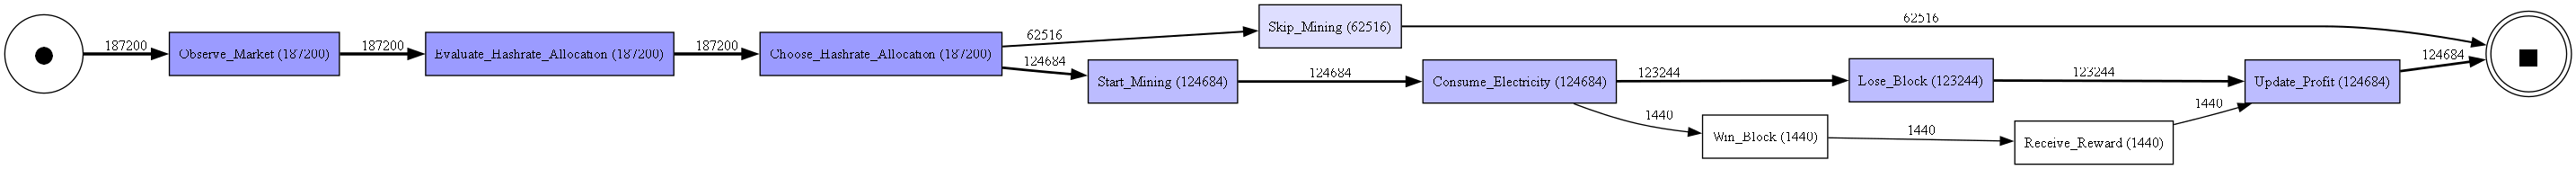

Saved DFG to: pm4py_outputs\01_dfg_agent_decision_process.png


In [15]:
if PM4PY_AVAILABLE:
    dfg, start_activities, end_activities = pm4py.discover_dfg(log)

    print("Start activities:", start_activities)
    print("End activities:", end_activities)
    print("Directly-follows edges:", len(dfg))

    # Display in notebook if graphviz is available.
    try:
        pm4py.view_dfg(dfg, start_activities, end_activities)
    except Exception as e:
        print("Could not display DFG inline:", e)

    # Save visualization to file.
    try:
        dfg_path = OUTPUT_DIR / "01_dfg_agent_decision_process.png"
        pm4py.save_vis_dfg(dfg, start_activities, end_activities, str(dfg_path))
        print("Saved DFG to:", dfg_path)
    except Exception as e:
        print("Could not save DFG:", e)
else:
    print("Install PM4Py to run process discovery.")

,variant,cases,share
0,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,123244,0.658355
1,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining,62516,0.333953
2,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,1440,0.007692


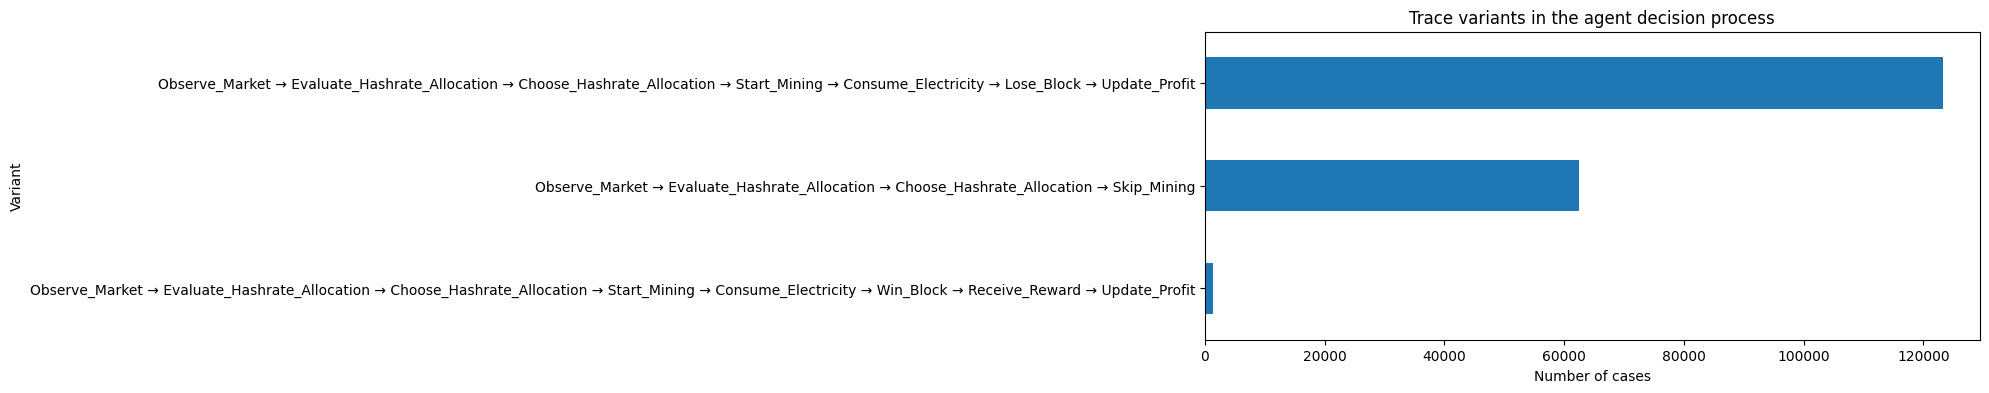

In [16]:
# Variant overview without relying on PM4Py
variant_counts = (
    case_summary["trace_string"]
    .value_counts()
    .rename_axis("variant")
    .reset_index(name="cases")
)
variant_counts["share"] = variant_counts["cases"] / variant_counts["cases"].sum()
display(variant_counts)

ax = variant_counts.sort_values("cases").plot(
    kind="barh",
    x="variant",
    y="cases",
    legend=False,
    figsize=(10, 4),
    title="Trace variants in the agent decision process"
)
ax.set_xlabel("Number of cases")
ax.set_ylabel("Variant")
plt.tight_layout()
plt.show()

Discovered Petri net with Inductive Miner.


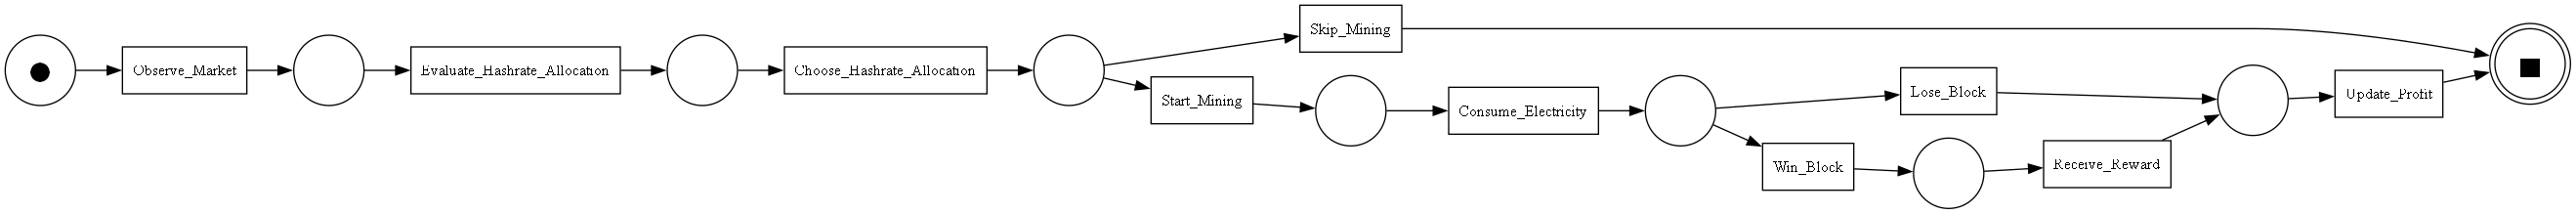

Saved Petri net to: pm4py_outputs\02_inductive_miner_petri_net.png


In [17]:
# Optional: discover a Petri net using the Inductive Miner.
# This is mostly useful for conformance checking and for showing a formal process model.
if PM4PY_AVAILABLE:
    try:
        net, im, fm = pm4py.discover_petri_net_inductive(log)
        print("Discovered Petri net with Inductive Miner.")
        try:
            pm4py.view_petri_net(net, im, fm)
        except Exception as e:
            print("Could not display Petri net inline:", e)
        try:
            petri_path = OUTPUT_DIR / "02_inductive_miner_petri_net.png"
            pm4py.save_vis_petri_net(net, im, fm, str(petri_path))
            print("Saved Petri net to:", petri_path)
        except Exception as e:
            print("Could not save Petri net:", e)
    except Exception as e:
        print("Could not discover Petri net:", e)

# Part 2 — Conformance checking against the intended behavior model

The intended process contains exactly three valid patterns:

1. Skip path  
   `Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining`

2. Mine and lose path  
   `Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lose_Block → Update_Profit`

3. Mine and win path  
   `Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Win_Block → Receive_Reward → Update_Profit`

This section performs two types of conformance checking:

- variant-level conformance: does the trace exactly match one expected trace?
- rule-level conformance: does the log violate important behavioral rules?

In [18]:
EXPECTED_TRACES = {
    (
        "Observe_Market",
        "Evaluate_Hashrate_Allocation",
        "Choose_Hashrate_Allocation",
        "Skip_Mining"
    ): "Expected skip path",
    (
        "Observe_Market",
        "Evaluate_Hashrate_Allocation",
        "Choose_Hashrate_Allocation",
        "Start_Mining",
        "Consume_Electricity",
        "Lose_Block",
        "Update_Profit"
    ): "Expected mine-loss path",
    (
        "Observe_Market",
        "Evaluate_Hashrate_Allocation",
        "Choose_Hashrate_Allocation",
        "Start_Mining",
        "Consume_Electricity",
        "Win_Block",
        "Receive_Reward",
        "Update_Profit"
    ): "Expected mine-win path"
}

case_summary["expected_trace"] = case_summary["trace"].isin(EXPECTED_TRACES.keys())
case_summary["expected_trace_label"] = case_summary["trace"].map(EXPECTED_TRACES).fillna("Unexpected trace")

conformance_summary = (
    case_summary["expected_trace_label"]
    .value_counts()
    .rename_axis("trace_conformance")
    .reset_index(name="cases")
)
conformance_summary["share"] = conformance_summary["cases"] / conformance_summary["cases"].sum()
display(conformance_summary)

unexpected_cases = case_summary.loc[~case_summary["expected_trace"]]
print("Unexpected cases:", len(unexpected_cases))
display(unexpected_cases.head(20))

,trace_conformance,cases,share
0,Expected mine-loss path,123244,0.658355
1,Expected skip path,62516,0.333953
2,Expected mine-win path,1440,0.007692


Unexpected cases: 0


,case:concept:name,trace,trace_string,trace_length,agent_type,org:resource,step,block_height,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,selected_allocation,potential_hashrate_th_s,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,realized_cost_usd,realized_revenue_usd,cumulative_profit_usd,reward_btc,outcome,decision,expected_trace,expected_trace_label


In [19]:
# Rule-level conformance checks
case_activity_sets = (
    event_log_df
    .groupby("case:concept:name")["concept:name"]
    .apply(set)
    .rename("activity_set")
    .reset_index()
)

case_order = (
    event_log_df
    .groupby("case:concept:name")["concept:name"]
    .apply(list)
    .rename("activity_list")
    .reset_index()
)

rules = case_summary[["case:concept:name", "trace", "outcome", "decision", "agent_type"]].copy()
rules = rules.merge(case_activity_sets, on="case:concept:name", how="left")
rules = rules.merge(case_order, on="case:concept:name", how="left")

def has(row, activity):
    return activity in row["activity_set"]

rules["starts_with_observe"] = rules["trace"].apply(lambda t: len(t) > 0 and t[0] == "Observe_Market")
rules["ends_validly"] = rules["trace"].apply(lambda t: len(t) > 0 and t[-1] in {"Skip_Mining", "Update_Profit"})
rules["skip_did_not_consume"] = ~rules.apply(lambda r: has(r, "Skip_Mining") and has(r, "Consume_Electricity"), axis=1)
rules["win_has_reward"] = rules.apply(lambda r: (not has(r, "Win_Block")) or has(r, "Receive_Reward"), axis=1)
rules["reward_requires_win"] = rules.apply(lambda r: (not has(r, "Receive_Reward")) or has(r, "Win_Block"), axis=1)
rules["lose_has_no_reward"] = rules.apply(lambda r: not (has(r, "Lose_Block") and has(r, "Receive_Reward")), axis=1)
rules["mining_requires_consumption"] = rules.apply(lambda r: (not has(r, "Start_Mining")) or has(r, "Consume_Electricity"), axis=1)

rule_cols = [
    "starts_with_observe",
    "ends_validly",
    "skip_did_not_consume",
    "win_has_reward",
    "reward_requires_win",
    "lose_has_no_reward",
    "mining_requires_consumption"
]

rule_summary = pd.DataFrame({
    "rule": rule_cols,
    "fitting_cases": [rules[c].sum() for c in rule_cols],
    "violating_cases": [(~rules[c]).sum() for c in rule_cols],
})
rule_summary["fit_share"] = rule_summary["fitting_cases"] / len(rules)
display(rule_summary)

violations = rules.loc[~rules[rule_cols].all(axis=1), ["case:concept:name", "agent_type", "outcome", "trace"] + rule_cols]
print("Cases violating at least one rule:", len(violations))
display(violations.head(20))

,rule,fitting_cases,violating_cases,fit_share
0,starts_with_observe,187200,0,1.0
1,ends_validly,187200,0,1.0
2,skip_did_not_consume,187200,0,1.0
3,win_has_reward,187200,0,1.0
4,reward_requires_win,187200,0,1.0
5,lose_has_no_reward,187200,0,1.0
6,mining_requires_consumption,187200,0,1.0


Cases violating at least one rule: 0


,case:concept:name,agent_type,outcome,trace,starts_with_observe,ends_validly,skip_did_not_consume,win_has_reward,reward_requires_win,lose_has_no_reward,mining_requires_consumption


In [20]:
# Block-level conformance: exactly one winner per block
if "block_height" in event_log_df.columns:
    win_events = event_log_df[event_log_df["concept:name"].eq("Win_Block")].copy()
    winners_per_block = (
        win_events
        .groupby("block_height")
        .agg(
            winners=("case:concept:name", "nunique"),
            winning_agents=("org:resource", lambda x: list(x.unique())),
            winning_agent_types=("agent_type", lambda x: list(x.unique()))
        )
        .reset_index()
    )

    all_blocks = pd.DataFrame({"block_height": sorted(event_log_df["block_height"].dropna().unique())})
    winners_per_block = all_blocks.merge(winners_per_block, on="block_height", how="left")
    winners_per_block["winners"] = winners_per_block["winners"].fillna(0).astype(int)

    block_conf = winners_per_block["winners"].value_counts().sort_index().rename_axis("winners_per_block").reset_index(name="blocks")
    display(block_conf)

    bad_blocks = winners_per_block[winners_per_block["winners"] != 1]
    print("Blocks with not exactly one winner:", len(bad_blocks))
    display(bad_blocks.head(20))

,winners_per_block,blocks
0,0,1440


Blocks with not exactly one winner: 1440


,block_height,winners,winning_agents,winning_agent_types
0,895275.0,0,NaN,NaN
1,895276.0,0,NaN,NaN
2,895277.0,0,NaN,NaN
3,895278.0,0,NaN,NaN
4,895279.0,0,NaN,NaN
5,895280.0,0,NaN,NaN
6,895281.0,0,NaN,NaN
7,895282.0,0,NaN,NaN
8,895283.0,0,NaN,NaN
9,895284.0,0,NaN,NaN


## Optional PM4Py token-based replay against an intended model

The rule checks above are faster and easier to explain.  
If you also want a formal PM4Py conformance result, the code below builds a small expected log with the three allowed variants, discovers a Petri net from that expected log, and replays a sample of actual cases against it.

Set `RUN_FULL_TOKEN_REPLAY = True` only if you want to run it on the full log. For large logs this can take time.

In [21]:
RUN_FULL_TOKEN_REPLAY = False
TOKEN_REPLAY_SAMPLE_CASES = 5000

if PM4PY_AVAILABLE:
    try:
        from pm4py.objects.log.obj import EventLog, Trace, Event

        expected_log = EventLog()
        for trace_tuple in EXPECTED_TRACES.keys():
            tr = Trace()
            for act in trace_tuple:
                tr.append(Event({"concept:name": act, "time:timestamp": pd.Timestamp("2025-01-01", tz="UTC")}))
            expected_log.append(tr)

        expected_net, expected_im, expected_fm = pm4py.discover_petri_net_inductive(expected_log)

        if RUN_FULL_TOKEN_REPLAY:
            replay_log = log
            print("Running token replay on full log.")
        else:
            sample_cases = case_summary["case:concept:name"].sample(
                min(TOKEN_REPLAY_SAMPLE_CASES, len(case_summary)),
                random_state=42
            )
            replay_df = event_log_df[event_log_df["case:concept:name"].isin(sample_cases)].copy()
            replay_log = pm4py.convert_to_event_log(replay_df)
            print(f"Running token replay on sample of {len(sample_cases)} cases.")

        fitness = pm4py.fitness_token_based_replay(replay_log, expected_net, expected_im, expected_fm)
        display(pd.DataFrame([fitness]))

    except Exception as e:
        print("Token-based replay could not be completed:", e)

Running token replay on sample of 5000 cases.


replaying log with TBR, completed traces :: 100%|██████████| 3/3 [00:00<00:00, 164.72it/s]


,perc_fit_traces,average_trace_fitness,log_fitness,percentage_of_fitting_traces
0,100.0,1.0,1.0,100.0


# Part 3 — Compare variants by agent type

This section compares how often each archetype follows the skip, mine-loss, or mine-win path.

outcome,Lose,Skip,Win,All
agent_type,,,,
Type 1: Dominant low-cost pools,2524,68,288,2880
Type 2: Large efficient pools,12409,1543,448,14400
Type 3: Lower/mid-scale pools,20202,5420,298,25920
Type 4: Small outside-network pools,88109,55485,406,144000
All,123244,62516,1440,187200


outcome,Lose,Skip,Win
agent_type,,,
Type 1: Dominant low-cost pools,87.64,2.36,10.00
Type 2: Large efficient pools,86.17,10.72,3.11
Type 3: Lower/mid-scale pools,77.94,20.91,1.15
Type 4: Small outside-network pools,61.19,38.53,0.28


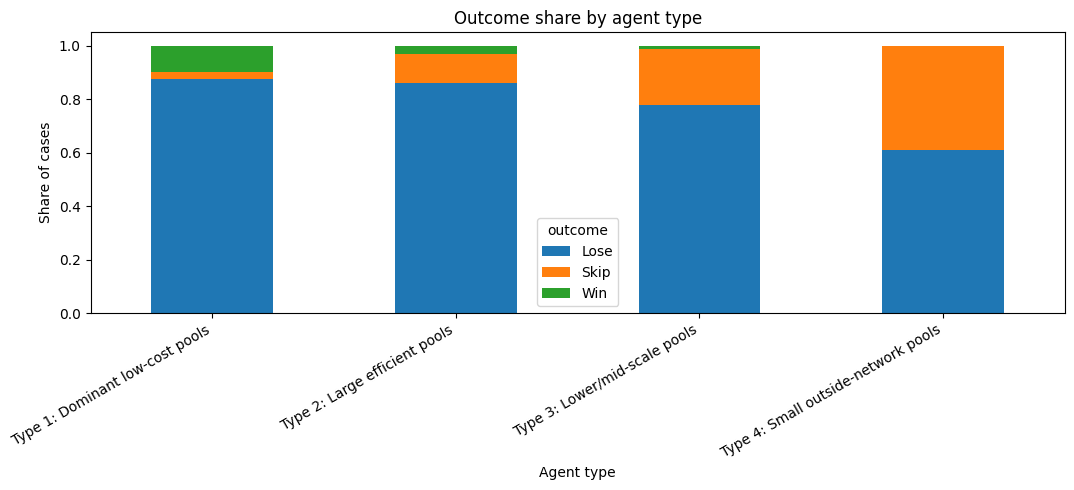

In [22]:
variant_by_type = pd.crosstab(
    case_summary["agent_type"],
    case_summary["outcome"],
    margins=True
)

variant_by_type_pct = pd.crosstab(
    case_summary["agent_type"],
    case_summary["outcome"],
    normalize="index"
)

display(variant_by_type)
display((variant_by_type_pct * 100).round(2))

# Plot outcome shares by agent type
plot_df = variant_by_type_pct.drop(index="All", errors="ignore") if "All" in variant_by_type_pct.index else variant_by_type_pct
ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    title="Outcome share by agent type"
)
ax.set_ylabel("Share of cases")
ax.set_xlabel("Agent type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# More detailed trace variant comparison by agent type
variant_type_table = (
    case_summary
    .groupby(["agent_type", "trace_string"])
    .size()
    .reset_index(name="cases")
)

variant_type_table["share_within_agent_type"] = (
    variant_type_table["cases"] /
    variant_type_table.groupby("agent_type")["cases"].transform("sum")
)

display(
    variant_type_table
    .sort_values(["agent_type", "cases"], ascending=[True, False])
)

# Agent-level outcome performance
agent_perf = (
    case_summary
    .groupby(["agent_type", "org:resource", "outcome"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for col in ["Skip", "Lose", "Win"]:
    if col not in agent_perf.columns:
        agent_perf[col] = 0

agent_perf["cases"] = agent_perf[["Skip", "Lose", "Win"]].sum(axis=1)
agent_perf["skip_rate"] = agent_perf["Skip"] / agent_perf["cases"]
agent_perf["win_rate"] = agent_perf["Win"] / agent_perf["cases"]
agent_perf["mine_rate"] = 1 - agent_perf["skip_rate"]

display(agent_perf.sort_values(["agent_type", "win_rate"], ascending=[True, False]).head(30))

,agent_type,trace_string,cases,share_within_agent_type
1,Type 1: Dominant low-cost pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,2524,0.876389
2,Type 1: Dominant low-cost pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,288,0.100000
0,Type 1: Dominant low-cost pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining,68,0.023611
4,Type 2: Large efficient pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,12409,0.861736
3,Type 2: Large efficient pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining,1543,0.107153
5,Type 2: Large efficient pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,448,0.031111
7,Type 3: Lower/mid-scale pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,20202,0.779398
6,Type 3: Lower/mid-scale pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining,5420,0.209105
8,Type 3: Lower/mid-scale pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Wi...,298,0.011497
10,Type 4: Small outside-network pools,Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lo...,88109,0.611868


outcome,agent_type,org:resource,Lose,Skip,Win,cases,skip_rate,win_rate,mine_rate
0,Type 1: Dominant low-cost pools,Type 1_001,1263,14,163,1440,0.009722,0.113194,0.990278
1,Type 1: Dominant low-cost pools,Type 1_002,1261,54,125,1440,0.037500,0.086806,0.962500
8,Type 2: Large efficient pools,Type 2_007,1248,116,76,1440,0.080556,0.052778,0.919444
2,Type 2: Large efficient pools,Type 2_001,1231,154,55,1440,0.106944,0.038194,0.893056
11,Type 2: Large efficient pools,Type 2_010,1263,127,50,1440,0.088194,0.034722,0.911806
10,Type 2: Large efficient pools,Type 2_009,1208,186,46,1440,0.129167,0.031944,0.870833
4,Type 2: Large efficient pools,Type 2_003,1227,172,41,1440,0.119444,0.028472,0.880556
9,Type 2: Large efficient pools,Type 2_008,1279,122,39,1440,0.084722,0.027083,0.915278
3,Type 2: Large efficient pools,Type 2_002,1249,153,38,1440,0.106250,0.026389,0.893750
5,Type 2: Large efficient pools,Type 2_004,1274,130,36,1440,0.090278,0.025000,0.909722


# Part 4 — Analyze the decision point: skip vs mine

The core decision point is:

`Choose_Hashrate_Allocation → Skip_Mining`  
or  
`Choose_Hashrate_Allocation → Start_Mining`

This section analyzes which variables separate skip cases from mining cases.

In [24]:
decision_features = [
    "selected_allocation",
    "allocated_hashrate_th_s",
    "power_kw",
    "expected_win_probability_vs_historical_network",
    "expected_revenue_usd",
    "expected_cost_usd",
    "expected_profit_usd",
    "best_allocation_profit_usd",
    "btc_price_at_block",
    "transaction_fees_btc",
    "total_reward_btc",
    "network_hashrate_th_s",
    "block_interval_minutes"
]
decision_features = [c for c in decision_features if c in case_summary.columns]

decision_df = case_summary[
    ["case:concept:name", "agent_type", "org:resource", "decision", "outcome"] + decision_features
].copy()

display(decision_df.head())

# Main decision summary
decision_summary = (
    decision_df
    .groupby(["agent_type", "decision"])
    .size()
    .reset_index(name="cases")
)
decision_summary["share_within_agent_type"] = (
    decision_summary["cases"] /
    decision_summary.groupby("agent_type")["cases"].transform("sum")
)
display(decision_summary)

# Numeric differences between skip and mine
numeric_decision_summary = (
    decision_df
    .groupby("decision")[decision_features]
    .agg(["mean", "median", "std"])
    .T
)
display(numeric_decision_summary)

,case:concept:name,agent_type,org:resource,decision,outcome,selected_allocation,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,btc_price_at_block,transaction_fees_btc,total_reward_btc,network_hashrate_th_s,block_interval_minutes
0,Type 1_001_block_895275,Type 1: Dominant low-cost pools,Type 1_001,Mine,Lose,1.1,3.601919e+07,819385.789655,0.042243,12544.882546,2513.677484,10031.205062,10031.205062,94723.80,0.010113,3.135113,8.526674e+08,5.183333
1,Type 1_001_block_895276,Type 1: Dominant low-cost pools,Type 1_001,Mine,Win,1.1,3.601919e+07,819385.789655,0.042243,12536.313491,1875.154908,10661.158584,10661.158584,94724.11,0.007961,3.132961,8.526674e+08,3.866667
2,Type 1_001_block_895277,Type 1: Dominant low-cost pools,Type 1_001,Mine,Lose,1.1,3.601919e+07,819385.789655,0.042243,12515.334331,929.494890,11585.839441,11585.839441,94724.11,0.002718,3.127718,8.526674e+08,1.916667
3,Type 1_001_block_895278,Type 1: Dominant low-cost pools,Type 1_001,Mine,Lose,1.1,3.601919e+07,819385.789655,0.042243,12502.205494,3249.190831,9253.014663,9253.014663,94470.70,0.007818,3.132818,8.526674e+08,6.700000
4,Type 1_001_block_895279,Type 1: Dominant low-cost pools,Type 1_001,Mine,Lose,1.1,3.601919e+07,819385.789655,0.042243,12533.096175,9585.921209,2947.174967,2947.174967,94224.23,0.023774,3.148774,8.526674e+08,19.766667


,agent_type,decision,cases,share_within_agent_type
0,Type 1: Dominant low-cost pools,Mine,2812,0.976389
1,Type 1: Dominant low-cost pools,Skip,68,0.023611
2,Type 2: Large efficient pools,Mine,12857,0.892847
3,Type 2: Large efficient pools,Skip,1543,0.107153
4,Type 3: Lower/mid-scale pools,Mine,20500,0.790895
5,Type 3: Lower/mid-scale pools,Skip,5420,0.209105
6,Type 4: Small outside-network pools,Mine,88515,0.614688
7,Type 4: Small outside-network pools,Skip,55485,0.385313


decision                                                       Mine  \
selected_allocation                            mean    1.063801e+00   
                                               median  1.100000e+00   
                                               std     1.411290e-01   
allocated_hashrate_th_s                        mean    7.845285e+06   
                                               median  5.652812e+06   
                                               std     7.215970e+06   
power_kw                                       mean    2.177704e+05   
                                               median  1.750618e+05   
                                               std     1.613922e+05   
expected_win_probability_vs_historical_network mean    9.200874e-03   
                                               median  6.629563e-03   
                                               std     8.462820e-03   
expected_revenue_usd                           mean    2.921773e+03   
                                               median  2.073153e+03   
                                               std     2.697727e+03   
expected_cost_usd                              mean    1.099572e+03   
                                               median  7.064430e+02   
                                               std     1.312566e+03   
expected_profit_usd                            mean    1.822201e+03   
                                               median  1.120686e+03   
                                               std     2.140441e+03   
best_allocation_profit_usd                     mean    1.822201e+03   
                                               median  1.120686e+03   
                                               std     2.140441e+03   
btc_price_at_block                             mean    1.004982e+05   
                                               median  1.027302e+05   
                                               std     3.846136e+03   
transaction_fees_btc                           mean    3.230396e-02   
                                               median  2.508871e-02   
                                               std     4.032256e-02   
total_reward_btc                               mean    3.157304e+00   
                                               median  3.150089e+00   
                                               std     4.032256e-02   
network_hashrate_th_s                          mean    8.526674e+08   
                                               median  8.526674e+08   
                                               std     3.291934e-08   
block_interval_minutes                         mean    4.736994e+00   
                                               median  3.950000e+00   
                                               std     3.890793e+00   

decision                                                       Skip  
selected_allocation                            mean    0.000000e+00  
                                               median  0.000000e+00  
                                               std     0.000000e+00  
allocated_hashrate_th_s                        mean    0.000000e+00  
                                               median  0.000000e+00  
                                               std     0.000000e+00  
power_kw                                       mean    0.000000e+00  
                                               median  0.000000e+00  
                                               std     0.000000e+00  
expected_win_probability_vs_historical_network mean    0.000000e+00  
                                               median  0.000000e+00  
                                               std     0.000000e+00  
expected_revenue_usd                           mean    0.000000e+00  
                                               median  0.000000e+00  
                                               std     0.000000e+00  
expected_cost_usd                      

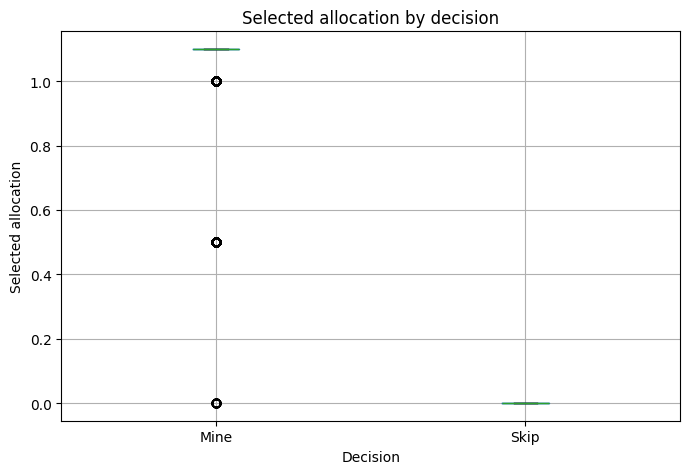

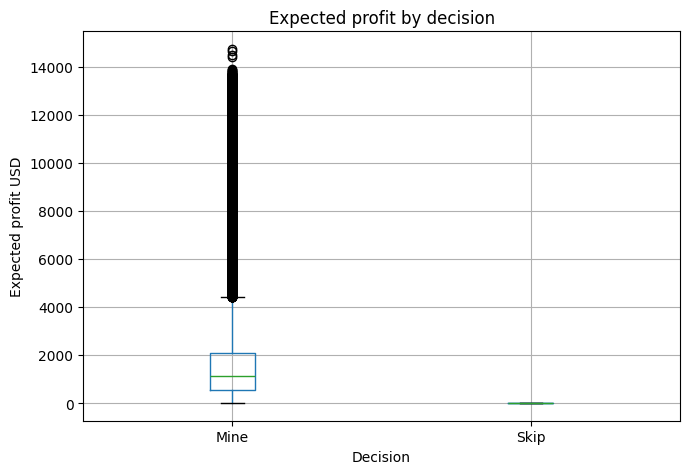

In [25]:
# Visualize the strongest direct variable: selected allocation
if "selected_allocation" in decision_df.columns:
    ax = decision_df.boxplot(
        column="selected_allocation",
        by="decision",
        figsize=(7, 5)
    )
    ax.set_title("Selected allocation by decision")
    ax.set_xlabel("Decision")
    ax.set_ylabel("Selected allocation")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

# Expected profit by decision
if "expected_profit_usd" in decision_df.columns:
    ax = decision_df.boxplot(
        column="expected_profit_usd",
        by="decision",
        figsize=(7, 5)
    )
    ax.set_title("Expected profit by decision")
    ax.set_xlabel("Decision")
    ax.set_ylabel("Expected profit USD")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

## Optional: simple decision model

This is not process discovery. It is decision mining / predictive explanation.

The goal is to test whether market and agent variables explain the branch:

- `Skip`
- `Mine`

Because the decision rules may be baked into the simulation, very high accuracy should not be interpreted as a real-world causal discovery. It means the generated behavior is strongly recoverable from the logged variables.

In [26]:
RUN_DECISION_MODEL = True
MAX_MODEL_ROWS = 60000

if RUN_DECISION_MODEL:
    try:
        from sklearn.model_selection import train_test_split
        from sklearn.compose import ColumnTransformer
        from sklearn.preprocessing import OneHotEncoder, StandardScaler
        from sklearn.pipeline import Pipeline
        from sklearn.linear_model import LogisticRegression
        from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

        model_df = decision_df.dropna(subset=["decision"]).copy()
        model_df["target_mine"] = (model_df["decision"] == "Mine").astype(int)

        feature_cols = decision_features + ["agent_type"]
        model_df = model_df.dropna(subset=feature_cols)

        if len(model_df) > MAX_MODEL_ROWS:
            model_df = model_df.sample(MAX_MODEL_ROWS, random_state=42)

        X = model_df[feature_cols]
        y = model_df["target_mine"]

        numeric_features = [c for c in decision_features if c in X.columns]
        categorical_features = ["agent_type"]

        preprocessor = ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numeric_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
            ]
        )

        clf = Pipeline(steps=[
            ("preprocess", preprocessor),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
        ])

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=42, stratify=y
        )

        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1]

        print("Classification report: target 1 = Mine, target 0 = Skip")
        print(classification_report(y_test, y_pred))
        print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
        print("Confusion matrix:")
        display(pd.DataFrame(
            confusion_matrix(y_test, y_pred),
            index=["actual_skip", "actual_mine"],
            columns=["pred_skip", "pred_mine"]
        ))

        # Coefficient interpretation
        feature_names = (
            numeric_features +
            list(clf.named_steps["preprocess"]
                 .named_transformers_["cat"]
                 .get_feature_names_out(categorical_features))
        )
        coefs = clf.named_steps["model"].coef_[0]
        coef_df = pd.DataFrame({
            "feature": feature_names,
            "coefficient_for_mine": coefs,
            "abs_coefficient": np.abs(coefs)
        }).sort_values("abs_coefficient", ascending=False)

        display(coef_df.head(25))

    except Exception as e:
        print("Decision model could not be completed:", e)

Classification report: target 1 = Mine, target 0 = Skip
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4983
           1       1.00      1.00      1.00     10017

    accuracy                           1.00     15000
   macro avg       1.00      1.00      1.00     15000
weighted avg       1.00      1.00      1.00     15000

ROC AUC: 1.0
Confusion matrix:


,pred_skip,pred_mine
actual_skip,4983,0
actual_mine,4,10013


,feature,coefficient_for_mine,abs_coefficient
0,selected_allocation,9.136371e+00,9.136371e+00
13,agent_type_Type 1: Dominant low-cost pools,5.949988e+00,5.949988e+00
5,expected_cost_usd,4.717847e+00,4.717847e+00
7,best_allocation_profit_usd,-1.640965e+00,1.640965e+00
6,expected_profit_usd,-1.640965e+00,1.640965e+00
2,power_kw,1.005827e+00,1.005827e+00
4,expected_revenue_usd,9.181213e-01,9.181213e-01
1,allocated_hashrate_th_s,8.971604e-01,8.971604e-01
3,expected_win_probability_vs_historical_network,8.971604e-01,8.971604e-01
16,agent_type_Type 4: Small outside-network pools,-4.084129e-01,4.084129e-01


# Part 5 — Link process outcomes to profitability and market conditions

This section treats the process path as an outcome:

- `Skip`
- `Lose`
- `Win`

Then it compares process outcomes on financial and market variables.

In [27]:
outcome_features = [
    "selected_allocation",
    "allocated_hashrate_th_s",
    "expected_win_probability_vs_historical_network",
    "expected_revenue_usd",
    "expected_cost_usd",
    "expected_profit_usd",
    "best_allocation_profit_usd",
    "realized_cost_usd",
    "realized_revenue_usd",
    "reward_btc",
    "cumulative_profit_usd",
    "btc_price_at_block",
    "transaction_fees_btc",
    "total_reward_btc",
    "network_hashrate_th_s",
    "block_interval_minutes"
]
outcome_features = [c for c in outcome_features if c in case_summary.columns]

outcome_summary = (
    case_summary
    .groupby("outcome")[outcome_features]
    .agg(["count", "mean", "median", "std"])
)

display(outcome_summary)

selected_allocation                             \
                      count      mean median       std   
outcome                                                  
Lose                 123244  1.064279    1.1  0.139402   
Skip                  62516  0.000000    0.0  0.000000   
Win                    1440  1.022917    1.1  0.244386   

        allocated_hashrate_th_s                                            \
                          count          mean        median           std   
outcome                                                                     
Lose                     123244  7.750279e+06  5.520522e+06  7.101564e+06   
Skip                      62516  0.000000e+00  0.000000e+00  0.000000e+00   
Win                        1440  1.597645e+07  1.242551e+07  1.120085e+07   

        expected_win_probability_vs_historical_network                      \
                                                 count      mean    median   
outcome                                                                      
Lose                                            123244  0.009089  0.006474   
Skip                                             62516  0.000000  0.000000   
Win                                               1440  0.018737  0.014573   

                  expected_revenue_usd                                         \
              std                count         mean       median          std   
outcome                                                                         
Lose     0.008329               123244  2886.091239  2058.628137  2654.300272   
Skip     0.000000                62516     0.000000     0.000000     0.000000   
Win      0.013136                 1440  5975.596917  4737.045706  4212.715438   

        expected_cost_usd                                        \
                    count         mean      median          std   
outcome                                                           
Lose               123244  1078.763546   701.55831  1263.287697   
Skip                62516     0.000000     0.00000     0.000000   
Win                  1440  2880.453477  1623.77734  3063.413425   

        expected_profit_usd                                         \
                      count         mean       median          std   
outcome                                                              
Lose                 123244  1807.327693  1114.930552  2123.864230   
Skip                  62516     0.000000     0.000000     0.000000   
Win                    1440  3095.143440  2027.742001  2999.746349   

        best_allocation_profit_usd                                         \
                             count         mean       median          std   
outcome                                                                     
Lose                        123244  1807.327693  1114.930552  2123.864230   
Skip                         62516     0.000000     0.000000     0.000000   
Win                           1440  3095.143440  2027.742001  2999.746349   

        realized_cost_usd                                        \
                    count         mean      median          std   
outcome                                                           
Lose               123244  1078.763546   701.55831  1263.287697   
Skip                    0          NaN         NaN          NaN   
Win                  1440  3201.809729  1863.89170  3207.892565   

        realized_revenue_usd                                             \
                       count           mean         median          std   
outcome                                                                   
Lose                       0            NaN            NaN          NaN   
Skip                       0            NaN            NaN          NaN   
Win                     1440  318607.262756  324713.368618  13812.04176   

        reward_btc                               cumulative_profit_usd  \
             count      m

In [28]:
# Outcome summary by agent type
outcome_by_type_financial = (
    case_summary
    .groupby(["agent_type", "outcome"])[outcome_features]
    .mean()
    .reset_index()
)

display(outcome_by_type_financial)

,agent_type,outcome,selected_allocation,allocated_hashrate_th_s,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,realized_cost_usd,realized_revenue_usd,reward_btc,cumulative_profit_usd,btc_price_at_block,transaction_fees_btc,total_reward_btc,network_hashrate_th_s,block_interval_minutes
0,Type 1: Dominant low-cost pools,Lose,1.096236,3.556044e+07,0.041705,13271.432431,3547.539240,9723.893190,9723.893190,3547.539240,NaN,NaN,1.986318e+07,100548.868237,0.039607,3.164607,8.526674e+08,7.724775
1,Type 1: Dominant low-cost pools,Skip,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,1.946456e+07,100421.863088,0.106367,3.231367,8.526674e+08,39.237745
2,Type 1: Dominant low-cost pools,Win,0.846875,2.746207e+07,0.032207,10299.230788,5542.133465,4757.097322,4757.097322,7148.914726,320670.085783,3.194794,2.043235e+07,100362.998750,0.069794,3.194794,8.526674e+08,21.032523
3,Type 2: Large efficient pools,Lose,1.078894,2.174993e+07,0.025508,8110.049429,2762.689523,5347.359906,5347.359906,2762.689523,NaN,NaN,5.147199e+06,100540.377440,0.038190,3.163190,8.526674e+08,7.150771
4,Type 2: Large efficient pools,Skip,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,5.082797e+06,100408.567816,0.091600,3.216600,8.526674e+08,31.029132
5,Type 2: Large efficient pools,Win,1.064732,2.195258e+07,0.025746,8209.658577,3830.951058,4378.707519,4378.707519,3830.951058,319095.100346,3.172483,5.886370e+06,100573.448683,0.047483,3.172483,8.526674e+08,10.050149
6,Type 3: Lower/mid-scale pools,Lose,1.068533,1.076588e+07,0.012626,4009.441479,1525.082502,2484.358977,2484.358977,1525.082502,NaN,NaN,1.646428e+06,100507.731895,0.034760,3.159760,8.526674e+08,5.809784
7,Type 3: Lower/mid-scale pools,Skip,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,1.699678e+06,100594.082972,0.080019,3.205019,8.526674e+08,24.851965
8,Type 3: Lower/mid-scale pools,Win,1.068792,1.094720e+07,0.012839,4083.279913,1761.636415,2321.643498,2321.643498,1761.636415,317795.863288,3.157858,1.933056e+06,100637.699262,0.032858,3.157858,8.526674e+08,6.506376
9,Type 4: Small outside-network pools,Lose,1.060330,4.290522e+06,0.005032,1595.296657,668.549347,926.747310,926.747310,668.549347,NaN,NaN,3.584370e+05,100488.102069,0.030508,3.155508,8.526674e+08,3.982741


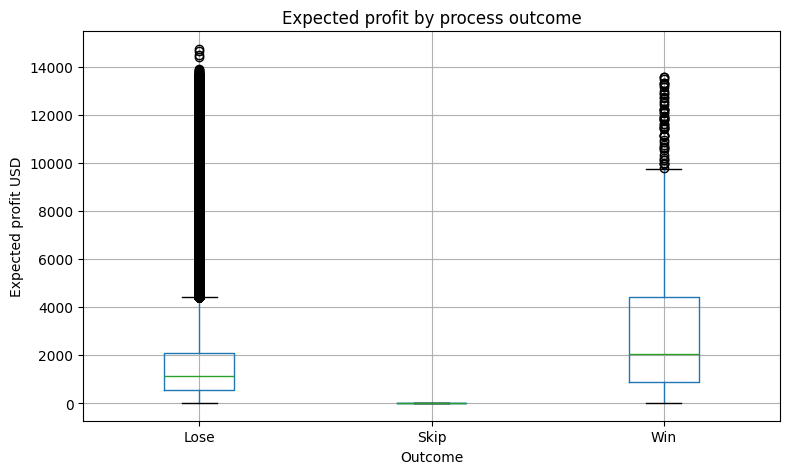

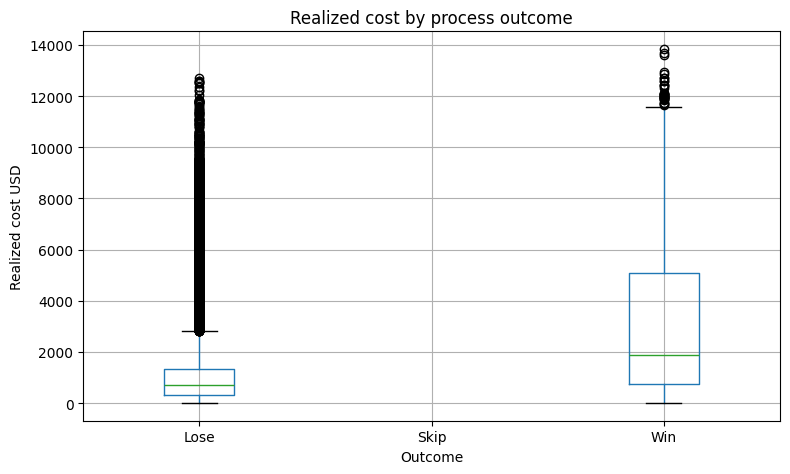

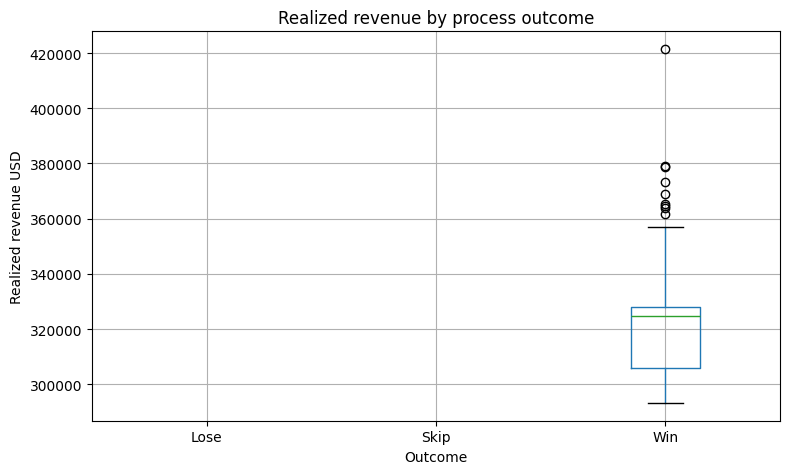

In [29]:
# Plot expected profit by outcome
if "expected_profit_usd" in case_summary.columns:
    ax = case_summary.boxplot(
        column="expected_profit_usd",
        by="outcome",
        figsize=(8, 5)
    )
    ax.set_title("Expected profit by process outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Expected profit USD")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

# Plot realized cost by outcome
if "realized_cost_usd" in case_summary.columns:
    ax = case_summary.boxplot(
        column="realized_cost_usd",
        by="outcome",
        figsize=(8, 5)
    )
    ax.set_title("Realized cost by process outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Realized cost USD")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

# Plot realized revenue by outcome
if "realized_revenue_usd" in case_summary.columns:
    ax = case_summary.boxplot(
        column="realized_revenue_usd",
        by="outcome",
        figsize=(8, 5)
    )
    ax.set_title("Realized revenue by process outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Realized revenue USD")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

## Market-condition bins

Here we bin market variables into quartiles and examine whether decision/outcome shares change across market regimes.


Market regime analysis: btc_price_at_block


decision,Mine,Skip
btc_price_at_block_quartile,,
"(93616.919, 96876.603]",65.42,34.58
"(96876.603, 102803.36]",70.65,29.35
"(102803.36, 103713.27]",64.30,35.70
"(103713.27, 105452.23]",66.00,34.00


outcome,Lose,Skip,Win
btc_price_at_block_quartile,,,
"(93616.919, 96876.603]",64.65,34.58,0.77
"(96876.603, 102803.36]",69.88,29.35,0.77
"(102803.36, 103713.27]",63.53,35.70,0.77
"(103713.27, 105452.23]",65.23,34.00,0.77


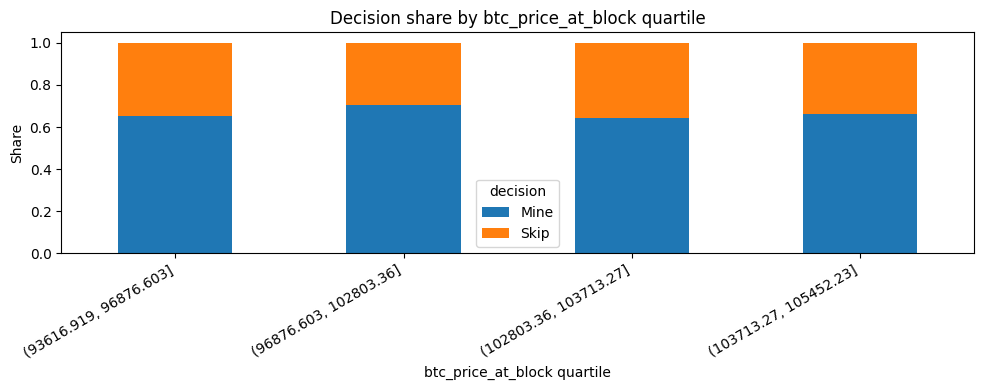


Market regime analysis: transaction_fees_btc


decision,Mine,Skip
transaction_fees_btc_quartile,,
"(-0.001, 0.0207]",99.13,0.87
"(0.0207, 0.0324]",83.29,16.71
"(0.0324, 0.0496]",54.41,45.59
"(0.0496, 0.931]",29.58,70.42


outcome,Lose,Skip,Win
transaction_fees_btc_quartile,,,
"(-0.001, 0.0207]",98.37,0.87,0.77
"(0.0207, 0.0324]",82.52,16.71,0.77
"(0.0324, 0.0496]",53.65,45.59,0.77
"(0.0496, 0.931]",28.81,70.42,0.77


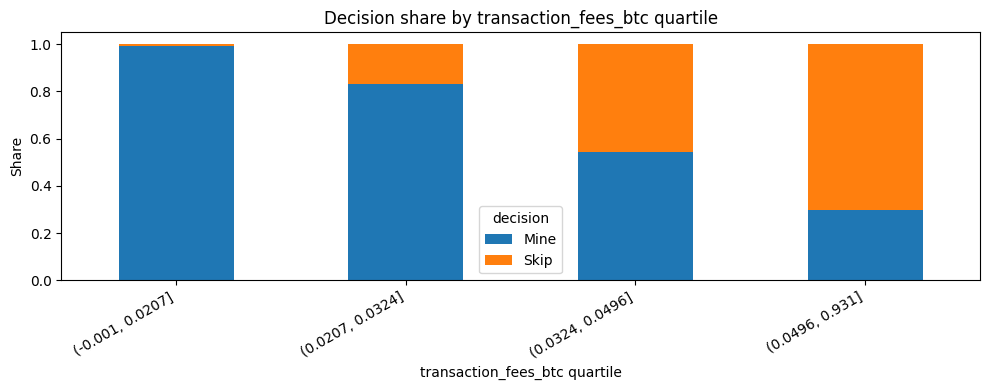


Market regime analysis: total_reward_btc


decision,Mine,Skip
total_reward_btc_quartile,,
"(3.124, 3.146]",99.13,0.87
"(3.146, 3.157]",83.29,16.71
"(3.157, 3.175]",54.41,45.59
"(3.175, 4.056]",29.58,70.42


outcome,Lose,Skip,Win
total_reward_btc_quartile,,,
"(3.124, 3.146]",98.37,0.87,0.77
"(3.146, 3.157]",82.52,16.71,0.77
"(3.157, 3.175]",53.65,45.59,0.77
"(3.175, 4.056]",28.81,70.42,0.77


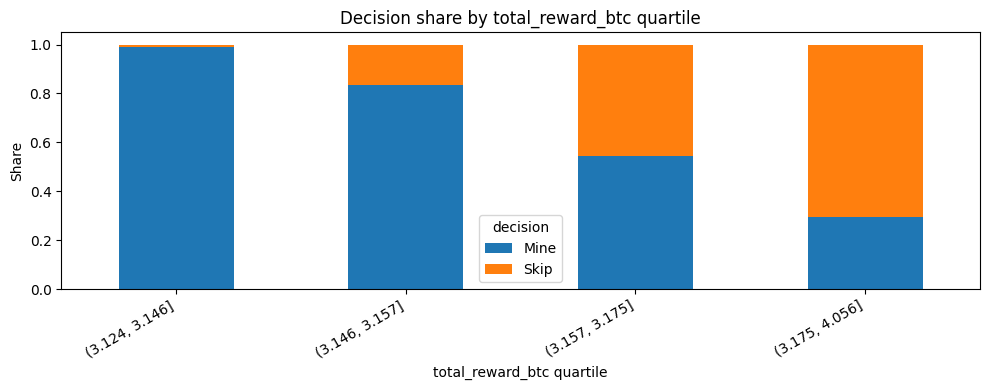

Skipping network_hashrate_th_s: fewer than 4 unique values.

Market regime analysis: block_interval_minutes


decision,Mine,Skip
block_interval_minutes_quartile,,
"(0.0157, 2.883]",100.00,0.00
"(2.883, 6.825]",100.00,0.00
"(6.825, 13.817]",58.17,41.83
"(13.817, 66.883]",8.11,91.89


outcome,Lose,Skip,Win
block_interval_minutes_quartile,,,
"(0.0157, 2.883]",99.23,0.00,0.77
"(2.883, 6.825]",99.23,0.00,0.77
"(6.825, 13.817]",57.40,41.83,0.77
"(13.817, 66.883]",7.34,91.89,0.77


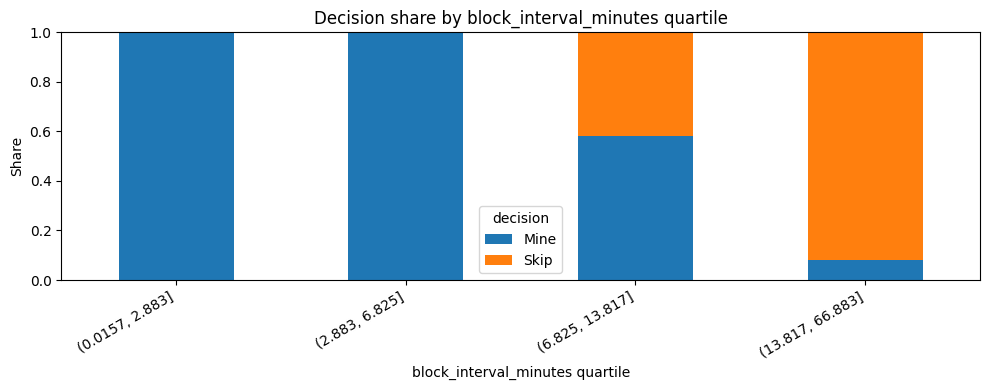

In [30]:
market_vars = [
    "btc_price_at_block",
    "transaction_fees_btc",
    "total_reward_btc",
    "network_hashrate_th_s",
    "block_interval_minutes"
]
market_vars = [c for c in market_vars if c in case_summary.columns]

for var in market_vars:
    tmp = case_summary[["outcome", "decision", "agent_type", var]].dropna().copy()
    if tmp[var].nunique() < 4:
        print(f"Skipping {var}: fewer than 4 unique values.")
        continue

    tmp[f"{var}_quartile"] = pd.qcut(tmp[var], q=4, duplicates="drop")

    print("\n" + "="*90)
    print(f"Market regime analysis: {var}")

    decision_by_bin = pd.crosstab(
        tmp[f"{var}_quartile"],
        tmp["decision"],
        normalize="index"
    )
    display((decision_by_bin * 100).round(2))

    outcome_by_bin = pd.crosstab(
        tmp[f"{var}_quartile"],
        tmp["outcome"],
        normalize="index"
    )
    display((outcome_by_bin * 100).round(2))

    ax = decision_by_bin.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 4),
        title=f"Decision share by {var} quartile"
    )
    ax.set_ylabel("Share")
    ax.set_xlabel(f"{var} quartile")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# Additional analysis — network/block-level checks

This section changes perspective from agent-case to block-level competition.

Use this to check:
- which archetype wins most blocks,
- whether higher-fee blocks attract more active mining,
- how many agents mine per block.

,block_height,cases,active_miners,skipping_agents,winners,avg_expected_profit_usd,btc_price_at_block,transaction_fees_btc,network_hashrate_th_s,winning_agent,winning_agent_type
0,895275.0,130,130,0,1,1359.009719,94723.80,0.010113,8.526674e+08,Type 4_026,Type 4: Small outside-network pools
1,895276.0,130,130,0,1,1650.383670,94724.11,0.007961,8.526674e+08,Type 1_001,Type 1: Dominant low-cost pools
2,895277.0,130,130,0,1,2080.251983,94724.11,0.002718,8.526674e+08,Type 2_009,Type 2: Large efficient pools
3,895278.0,130,130,0,1,1014.739992,94470.70,0.007818,8.526674e+08,Type 2_006,Type 2: Large efficient pools
4,895279.0,130,8,122,1,59.347071,94224.23,0.023774,8.526674e+08,Type 2_007,Type 2: Large efficient pools


,winning_agent_type,blocks
0,Type 2: Large efficient pools,448
1,Type 4: Small outside-network pools,406
2,Type 3: Lower/mid-scale pools,298
3,Type 1: Dominant low-cost pools,288


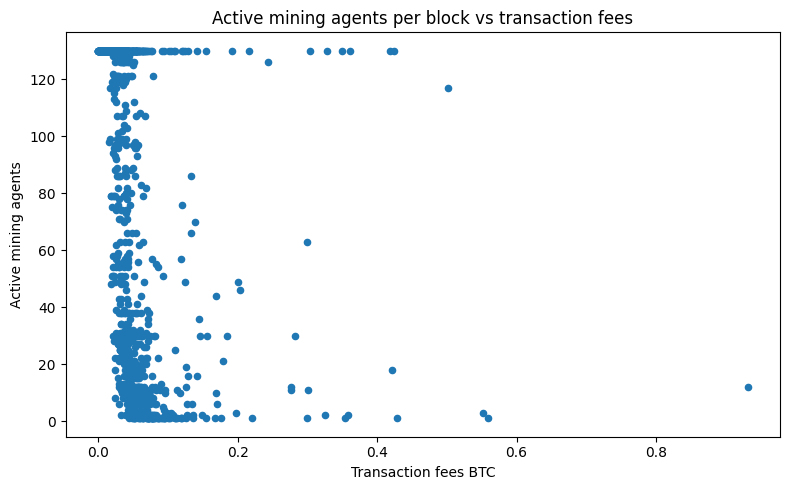

In [31]:
block_level = (
    case_summary
    .groupby(["block_height"])
    .agg(
        block_time=("time:timestamp", "first") if "time:timestamp" in case_summary.columns else ("case:concept:name", "count"),
    )
) if False else None

# Build block-level table from case_summary
block_group_cols = ["block_height"]
if "block_height" in case_summary.columns:
    block_summary = (
        case_summary
        .groupby("block_height")
        .agg(
            cases=("case:concept:name", "nunique"),
            active_miners=("decision", lambda s: (s == "Mine").sum()),
            skipping_agents=("decision", lambda s: (s == "Skip").sum()),
            winners=("outcome", lambda s: (s == "Win").sum()),
            avg_expected_profit_usd=("expected_profit_usd", "mean") if "expected_profit_usd" in case_summary.columns else ("case:concept:name", "count"),
            btc_price_at_block=("btc_price_at_block", "first") if "btc_price_at_block" in case_summary.columns else ("case:concept:name", "count"),
            transaction_fees_btc=("transaction_fees_btc", "first") if "transaction_fees_btc" in case_summary.columns else ("case:concept:name", "count"),
            network_hashrate_th_s=("network_hashrate_th_s", "first") if "network_hashrate_th_s" in case_summary.columns else ("case:concept:name", "count")
        )
        .reset_index()
    )

    win_cases = case_summary[case_summary["outcome"].eq("Win")][["block_height", "org:resource", "agent_type"]].copy()
    win_cases = win_cases.rename(columns={
        "org:resource": "winning_agent",
        "agent_type": "winning_agent_type"
    })
    block_summary = block_summary.merge(win_cases, on="block_height", how="left")

    display(block_summary.head())
    display(block_summary["winning_agent_type"].value_counts(dropna=False).rename_axis("winning_agent_type").reset_index(name="blocks"))

    if "transaction_fees_btc" in block_summary.columns:
        ax = block_summary.plot(
            kind="scatter",
            x="transaction_fees_btc",
            y="active_miners",
            figsize=(8, 5),
            title="Active mining agents per block vs transaction fees"
        )
        ax.set_xlabel("Transaction fees BTC")
        ax.set_ylabel("Active mining agents")
        plt.tight_layout()
        plt.show()

# Export analysis tables

The following cell saves the most useful tables to CSV files in `pm4py_outputs/`.

In [32]:
exports = {
    "case_summary.csv": case_summary,
    "variant_counts.csv": variant_counts,
    "conformance_summary.csv": conformance_summary,
    "rule_summary.csv": rule_summary,
    "variant_by_agent_type_counts.csv": variant_by_type.reset_index(),
    "variant_by_agent_type_percentages.csv": (variant_by_type_pct * 100).round(4).reset_index(),
    "decision_summary.csv": decision_summary,
    "outcome_by_type_financial_means.csv": outcome_by_type_financial
}

for filename, table in exports.items():
    path = OUTPUT_DIR / filename
    table.to_csv(path, index=False)
    print("Saved:", path)

Saved: pm4py_outputs\case_summary.csv
Saved: pm4py_outputs\variant_counts.csv
Saved: pm4py_outputs\conformance_summary.csv
Saved: pm4py_outputs\rule_summary.csv
Saved: pm4py_outputs\variant_by_agent_type_counts.csv
Saved: pm4py_outputs\variant_by_agent_type_percentages.csv
Saved: pm4py_outputs\decision_summary.csv
Saved: pm4py_outputs\outcome_by_type_financial_means.csv


# Suggested interpretation for your report

You can frame the analysis as follows:

## Research angle

> Process mining is used to validate and analyze an agent-based simulation of Bitcoin mining-pool behavior under historical market conditions.

## Main findings to report

1. **The discovered process is simple but meaningful.**  
   The log contains three main variants: skip, mine-loss, and mine-win.

2. **Conformance is the key methodological contribution.**  
   Since the behavior was generated by agents, PM4Py is useful for validating whether the event log follows the intended behavioral protocol.

3. **Agent archetypes differ strongly.**  
   Dominant low-cost pools should mine more often and win more often; small outside-network pools should skip more often and win rarely.

4. **The decision point is the most important analytical location.**  
   The branch after `Choose_Hashrate_Allocation` can be analyzed using selected allocation, expected cost, expected revenue, expected profit, BTC price, transaction fees, and agent type.

5. **Outcome mining links process paths to economic meaning.**  
   Skip cases avoid direct mining cost, mine-loss cases incur cost without reward, and mine-win cases receive block reward and fees.

## Limitation


> PM4Py helps inspect, validate, and compare the simulated behavior generated by the mining-pool agents.